In [2]:
import pandas as pd
import ast

# 1. Cargar los datos crudos que guardamos desde Kafka
df_crudo = pd.read_csv('../datos_crudos_kafka.csv')

# 2. Como los guardamos en CSV, los diccionarios se volvieron texto. 
# Usamos ast.literal_eval para convertirlos de vuelta a diccionarios de Python reales.
df_crudo['metadata'] = df_crudo['metadata'].apply(ast.literal_eval)
df_crudo['data'] = df_crudo['data'].apply(ast.literal_eval)

# 3. Aplanar las columnas anidadas
df_meta = pd.json_normalize(df_crudo['metadata'])
df_data = pd.json_normalize(df_crudo['data'])

# 4. Unir todo en un solo DataFrame
df_completo = pd.concat([df_meta, df_data], axis=1)

print(f"Dimensiones del dataset aplanado: {df_completo.shape}")

# 5. Identificar las columnas disponibles por cada año
columnas_por_ano = {}
for ano in df_completo['year'].unique():
    # Extraemos solo los datos de ese año y botamos las columnas que estén 100% vacías (NaN)
    df_ano = df_completo[df_completo['year'] == ano].dropna(axis=1, how='all')
    columnas_por_ano[ano] = set(df_ano.columns)
    print(f"\n--- Año {ano} ---")
    print(f"Total variables: {len(df_ano.columns)}")
    # Mostramos una muestra de las columnas
    print(list(df_ano.columns)[:5], "...")

Dimensiones del dataset aplanado: (782, 33)

--- Año 2015 ---
Total variables: 15
['source_file', 'year', 'record_id', 'Country', 'Region'] ...

--- Año 2016 ---
Total variables: 16
['source_file', 'year', 'record_id', 'Country', 'Region'] ...

--- Año 2017 ---
Total variables: 15
['source_file', 'year', 'record_id', 'Country', 'Family'] ...

--- Año 2018 ---
Total variables: 12
['source_file', 'year', 'record_id', 'Generosity', 'Overall rank'] ...

--- Año 2019 ---
Total variables: 12
['source_file', 'year', 'record_id', 'Generosity', 'Overall rank'] ...


Lógica de Integración (Merge Logic) y Transformaciones

Enfoque: Se implementó un mapeo de esquemas basado en diccionarios (Schema Mapping). Se identificó que variables conceptualmente idénticas cambiaron de nomenclatura entre 2015 y 2019 (ej. Family pasó a Social support; Economy (GDP per Capita) pasó a GDP per capita). Se estandarizaron estos nombres hacia una estructura única consolidada.

Limitaciones: Al fusionar variables como Family y Social support bajo una misma característica, asumimos una equivalencia directa 1:1. Es posible que la metodología de las encuestas originales haya variado ligeramente en esos años, introduciendo un ligero ruido o desviación metodológica en la serie de tiempo.

In [3]:
# 1. Diccionario de estandarización para resolver la evolución del esquema
renaming_dict = {
    'Happiness Score': 'Happiness_Score',
    'Happiness.Score': 'Happiness_Score',
    'Score': 'Happiness_Score',
    
    'Economy (GDP per Capita)': 'GDP_per_Capita',
    'Economy..GDP.per.Capita.': 'GDP_per_Capita',
    'GDP per capita': 'GDP_per_Capita',
    
    'Family': 'Social_Support',
    'Social support': 'Social_Support',
    
    'Health (Life Expectancy)': 'Life_Expectancy',
    'Health..Life.Expectancy.': 'Life_Expectancy',
    'Healthy life expectancy': 'Life_Expectancy',
    
    'Freedom': 'Freedom',
    'Freedom to make life choices': 'Freedom',
    
    'Trust (Government Corruption)': 'Corruption',
    'Trust..Government.Corruption.': 'Corruption',
    'Perceptions of corruption': 'Corruption',
    
    'Generosity': 'Generosity',
    
    'Country': 'Country',
    'Country or region': 'Country'
}

# 2. Aplicamos el renombramiento de columnas
df_renombrado = df_completo.rename(columns=renaming_dict)

# 3. Consolidamos las columnas
# Transponemos (.T), agrupamos por el nombre de la variable y volvemos a transponer (.T)
df_clean = df_renombrado.T.groupby(level=0).first().T

# 4. Seleccionamos estrictamente el subset de variables para Machine Learning
columnas_ml = [
    'year', 'Country', 'Happiness_Score', 'GDP_per_Capita', 
    'Social_Support', 'Life_Expectancy', 'Freedom', 'Corruption', 'Generosity'
]
df_ml = df_clean[columnas_ml].copy()

# 5. Forzamos los tipos de datos correctos (las métricas a numérico)
cols_numericas = ['Happiness_Score', 'GDP_per_Capita', 'Social_Support', 
                  'Life_Expectancy', 'Freedom', 'Corruption', 'Generosity']
df_ml[cols_numericas] = df_ml[cols_numericas].apply(pd.to_numeric, errors='coerce')

print("--- Valores Nulos tras la consolidación ---")
print(df_ml.isnull().sum())
print(f"\nNueva dimensión del dataset: {df_ml.shape}")

--- Valores Nulos tras la consolidación ---
year               0
Country            0
Happiness_Score    0
GDP_per_Capita     0
Social_Support     0
Life_Expectancy    0
Freedom            0
Corruption         1
Generosity         0
dtype: int64

Nueva dimensión del dataset: (782, 9)


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Tratamiento de valores faltantes
# Rellenamos el único nulo en 'Corruption' con la mediana de esa columna
mediana_corrupcion = df_ml['Corruption'].median()
df_ml['Corruption'] = df_ml['Corruption'].fillna(mediana_corrupcion)

print("Nulos restantes:", df_ml['Corruption'].isnull().sum())

# 2. Estadísticas descriptivas
print("\n--- Estadísticas Descriptivas ---")
display(df_ml.describe())

Nulos restantes: 0

--- Estadísticas Descriptivas ---


,Happiness_Score,GDP_per_Capita,Social_Support,Life_Expectancy,Freedom,Corruption,Generosity
count,782.000000,782.000000,782.000000,782.000000,782.000000,782.000000,782.000000
mean,5.379018,0.916047,1.078392,0.612416,0.411091,0.125392,0.218576
std,1.127456,0.407340,0.329548,0.248309,0.152880,0.105756,0.122321
min,2.693000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.509750,0.606500,0.869363,0.440183,0.309768,0.054250,0.130000
50%,5.322000,0.982205,1.124735,0.647310,0.431000,0.091000,0.201982
75%,6.189500,1.236187,1.327250,0.808000,0.531000,0.155861,0.278832
max,7.769000,2.096000,1.644000,1.141000,0.724000,0.551910,0.838075


Estrategia de Entrenamiento y Preprocesamiento

Variables: La variable objetivo (Target) es Happiness_Score y las predictoras (Features) son las 6 variables socioeconómicas numéricas.   

Prevención de Data Leakage: Para garantizar que la información del conjunto de prueba no influya en el entrenamiento, se implementó un Pipeline. El StandardScaler se ajusta (fit) estrictamente con los datos de entrenamiento y luego solo transforma el conjunto de prueba.   

Selección del Algoritmo: Se eligió RandomForestRegressor por encima de la Regresión Lineal simple. Como vimos en el EDA, variables como el PIB y la Esperanza de Vida tienen relaciones fuertes pero con cierta dispersión no lineal; un modelo basado en árboles captura mejor estas interacciones complejas sin requerir transformaciones polinómicas manuales.   

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor

# 1. Definir variable objetivo (y) y predictoras (X)
columnas_predictoras = ['GDP_per_Capita', 'Social_Support', 'Life_Expectancy', 
                        'Freedom', 'Corruption', 'Generosity']
X = df_ml[columnas_predictoras]
y = df_ml['Happiness_Score']

# 2. Separar en datos de entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Registros para entrenar: {X_train.shape[0]}")
print(f"Registros para probar: {X_test.shape[0]}")

# 3 y 4. Crear el Pipeline (Escalado + Modelo) y Entrenar
modelo_pipeline = Pipeline([
    ('escalador', StandardScaler()),
    ('regresor', RandomForestRegressor(n_estimators=100, random_state=42))
])

# Entrenamos el modelo
modelo_pipeline.fit(X_train, y_train)

print("\n¡El modelo se ha entrenado exitosamente!")

Registros para entrenar: 625
Registros para probar: 157

¡El modelo se ha entrenado exitosamente!


Evaluación del Modelo y Posibles Mejoras

Interpretación de Métricas: Se calcularon el MAE, MSE, RMSE y R^2. El coeficiente R^2 nos indica qué porcentaje de la variabilidad en la felicidad es explicada por las variables socioeconómicas. El RMSE penaliza los errores grandes, dándonos una medida clara de la desviación promedio de nuestras predicciones frente a la realidad.  

Análisis Visual: La gráfica de "Reales vs Predichos" compara los resultados del modelo contra la línea roja de predicción perfecta. Adicionalmente, graficamos la "Importancia de las variables" para entender qué factores pesan más en la decisión del modelo.

Oportunidades de Mejora: El rendimiento podría aumentar si hacemos una búsqueda exhaustiva de hiperparámetros (ej. profundidad máxima de los árboles) mediante validación cruzada. También descartamos la columna categórica "Region" por complejidad en la integración histórica; incluirla a futuro con One-Hot Encoding le daría más contexto regional al modelo.


--- Métricas de Rendimiento (Datos de Prueba) ---
MAE (Error Absoluto Medio): 0.4051
MSE (Error Cuadrático Medio): 0.2816
RMSE (Raíz del Error Cuadrático Medio): 0.5307
R² (Coeficiente de Determinación): 0.7817


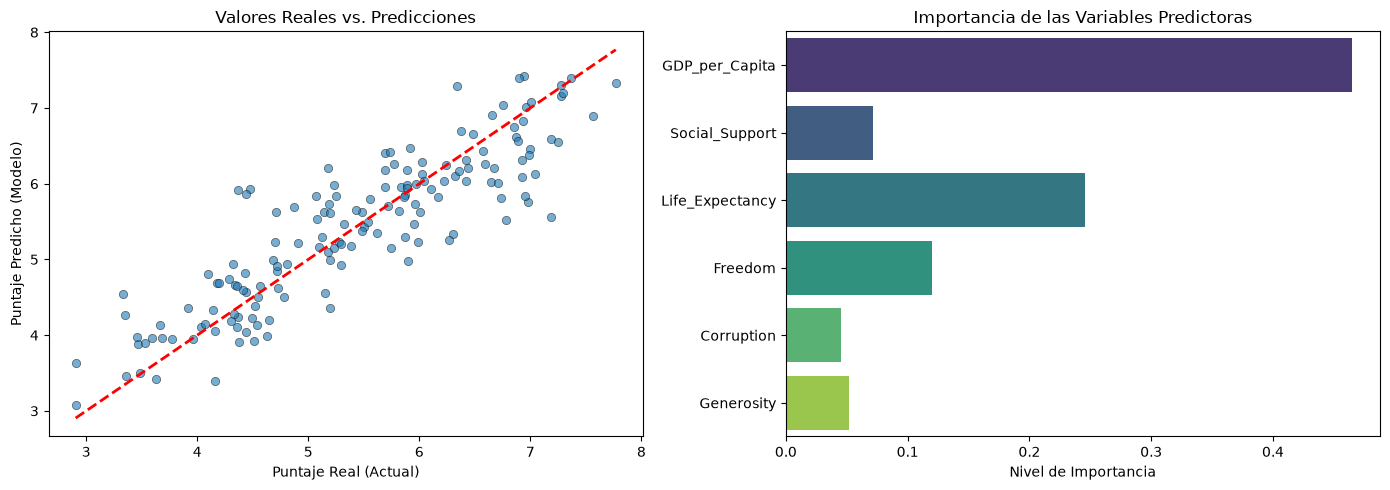

In [8]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Hacer predicciones con los datos de prueba
y_pred = modelo_pipeline.predict(X_test)

# 2. Calcular las métricas de regresión solicitadas
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("--- Métricas de Rendimiento (Datos de Prueba) ---")
print(f"MAE (Error Absoluto Medio): {mae:.4f}")
print(f"MSE (Error Cuadrático Medio): {mse:.4f}")
print(f"RMSE (Raíz del Error Cuadrático Medio): {rmse:.4f}")
print(f"R² (Coeficiente de Determinación): {r2:.4f}")

# 3. Visualización del rendimiento del modelo
plt.figure(figsize=(14, 5))

# Gráfico A: Valores Reales vs Predicciones
plt.subplot(1, 2, 1)
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6, edgecolor='k')
# Dibujamos la línea de predicción perfecta
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Puntaje Real (Actual)')
plt.ylabel('Puntaje Predicho (Modelo)')
plt.title('Valores Reales vs. Predicciones')

# Gráfico B: Importancia de las variables en el Random Forest
plt.subplot(1, 2, 2)
# Extraemos el algoritmo del pipeline para ver qué variables usó más
importancias = modelo_pipeline.named_steps['regresor'].feature_importances_
sns.barplot(x=importancias, y=columnas_predictoras, hue=columnas_predictoras, palette='viridis', legend=False)
plt.xlabel('Nivel de Importancia')
plt.title('Importancia de las Variables Predictoras')

plt.tight_layout()
plt.show()

In [9]:
from sqlalchemy import create_engine
import numpy as np

# 1. Armamos un DataFrame final uniendo las variables, el valor real y nuestra predicción
df_resultados = X_test.copy()
df_resultados['Actual_Happiness'] = y_test
df_resultados['Predicted_Happiness'] = np.round(y_pred, 4)

# 2. Configuración de conexión a tu PostgreSQL en GCP
DB_USER = "alexelgordo"
DB_PASS = "password_etl_2026"
DB_HOST = "35.254.253.219"  # IP Externa de la máquina etl-ws3
DB_PORT = "5432"
DB_NAME = "workshop3"

# 3. Crear el motor de conexión
cadena_conexion = f'postgresql+psycopg2://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}'
engine = create_engine(cadena_conexion)

# 4. Cargar los datos a la base de datos
print("Conectando a PostgreSQL en Google Cloud y subiendo datos...")
df_resultados.to_sql('happiness_predictions', engine, if_exists='replace', index=False)

print("¡Carga exitosa! La tabla 'happiness_predictions' ya está en tu servidor.")

Conectando a PostgreSQL en Google Cloud y subiendo datos...
¡Carga exitosa! La tabla 'happiness_predictions' ya está en tu servidor.


In [10]:
import pandas as pd

# Consultamos los primeros 5 registros directamente desde la base de datos en la nube
query = "SELECT * FROM happiness_predictions LIMIT 5;"
df_verificacion = pd.read_sql(query, engine)

print("Datos leídos directamente desde PostgreSQL en etl-ws3:")
display(df_verificacion)

Datos leídos directamente desde PostgreSQL en etl-ws3:


,GDP_per_Capita,Social_Support,Life_Expectancy,Freedom,Corruption,Generosity,Actual_Happiness,Predicted_Happiness
0,1.35943,1.08113,0.77758,0.46823,0.12275,0.22202,7.039,6.1299
1,0.34193,0.76062,0.15010,0.23501,0.05269,0.18386,3.667,4.1358
2,0.91800,1.31400,0.67200,0.58500,0.05000,0.30700,4.471,5.9305
3,1.56391,1.21963,0.91894,0.61583,0.37798,0.28034,6.946,7.4225
4,1.24400,1.43300,0.88800,0.46400,0.08200,0.26200,7.190,6.5900
